# Mašinsko učenje — Vežba 1 — Zadatak 4
## L2 regularizacija (Ridge regresija)

Za funkciju cilja biramo

$$
E_\lambda(\mathbf w) = \frac{1}{2N}\sum_{i=1}^N(y_i-\hat y_i)^2
+\lambda\sum_{j=1}^M w_j^2.
$$

Slobodni član $w_0$ **nije** uključen u kaznu.
Neka je $D=\mathrm{diag}(0,1,\ldots,1)$. Iz uslova $\nabla E_\lambda=0$ sledi

$$ (\Phi^T\Phi+2N\lambda D)\mathbf w=\Phi^T\mathbf y. $$

Detaljno izvođenje nalazi se u `zadatak_4_izvod.md`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from poly_regression import PolynomialRegression

Path('rezultati').mkdir(exist_ok=True)
frame = pd.read_csv('podaci.csv')
X = frame[['X']].to_numpy()
y = frame['Y'].to_numpy()
stepeni = [1, 2, 3, 5, 9]
lambde = [0.0, 0.01, 1.0, 100.0]
novo_X = np.array([600., 900., 1300., 1600.])

rezultati = []
modeli = {}
for M in stepeni:
    for lam in lambde:
        model = PolynomialRegression(degree=M, alpha=lam).fit(X, y)
        modeli[(M, lam)] = model
        rezultati.append({
            'M': M,
            'lambda': lam,
            'MSE_obuka': model.score(X, y),
            'Err_bez_kazne': model.score(X, y)/2,
            'L2_norma_w1_do_wM': np.linalg.norm(model.coef_[1:]),
            'funkcija_cilja': model.objective(X, y),
            'Y_pred_1600': model.predict([[1600]])[0],
        })

pregled = pd.DataFrame(rezultati)
display(pregled.round(7))
pregled.to_csv('rezultati/zadatak_4_poredjenje.csv', index=False)

,M,lambda,MSE_obuka,Err_bez_kazne,L2_norma_w1_do_wM,funkcija_cilja,Y_pred_1600
0,1,0.00,0.748453,0.374227,0.001593,0.374227,5.837944
1,1,0.01,0.748453,0.374227,0.001593,0.374227,5.837944
2,1,1.00,0.748453,0.374227,0.001593,0.374229,5.837925
3,1,100.00,0.748454,0.374227,0.001590,0.374480,5.835995
4,2,0.00,0.057551,0.028776,0.020442,0.028776,3.528475
5,2,0.01,0.057551,0.028776,0.020442,0.028780,3.528498
6,2,1.00,0.057552,0.028776,0.020421,0.029193,3.530798
7,2,100.00,0.064730,0.032365,0.018502,0.066598,3.738935
8,3,0.00,0.016553,0.008277,0.005263,0.008277,2.689484
9,3,0.01,0.016553,0.008277,0.005261,0.008277,2.689534


### Poređenje modela bez i sa regularizacijom

Za prikaz koristimo $\lambda=100$ kako bi se efekat kazne jasno video i kod nenormalizovanih X vrednosti u milimetrima.

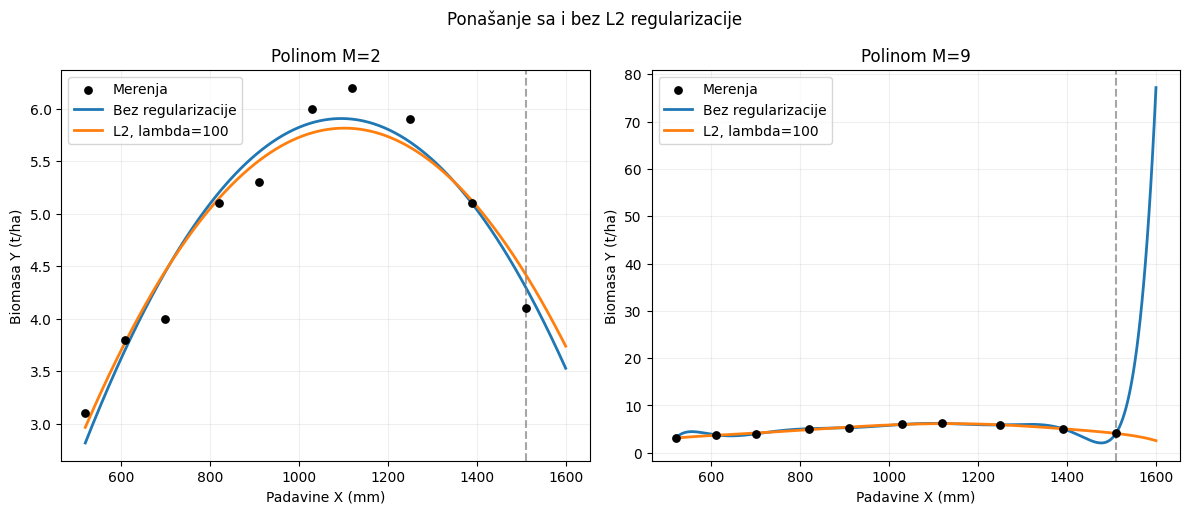

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=False)
xs = np.linspace(520, 1600, 550)
for ax, M in zip(axes, [2, 9]):
    ax.scatter(X[:, 0], y, c='black', s=28, zorder=5, label='Merenja')
    for lam in [0.0, 100.0]:
        ax.plot(xs, modeli[(M, lam)].predict(xs), lw=2,
                label='Bez regularizacije' if lam == 0 else 'L2, lambda=100')
    ax.axvline(1510, ls='--', c='grey', alpha=.7)
    ax.set(title=f'Polinom M={M}', xlabel='Padavine X (mm)', ylabel='Biomasa Y (t/ha)')
    ax.grid(alpha=.2)
    ax.legend()
fig.suptitle('Ponašanje sa i bez L2 regularizacije')
fig.tight_layout()
fig.savefig('rezultati/zadatak_4_krive.png', dpi=180)
plt.show()

### Promena MSE pri različitim vrednostima regularizacije

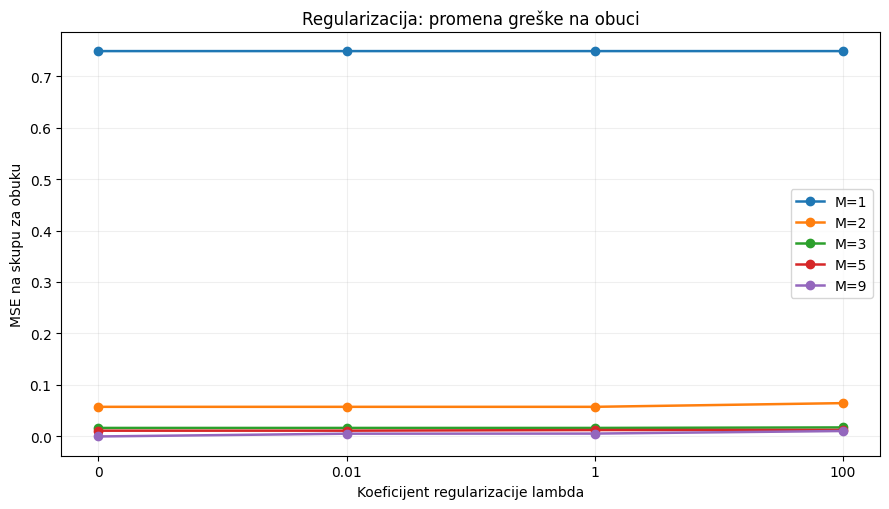

In [3]:
fig, ax = plt.subplots(figsize=(9, 5.2))
for M in stepeni:
    tbl = pregled.loc[pregled['M']==M]
    ax.plot(range(len(lambde)), tbl['MSE_obuka'], marker='o', lw=1.8, label=f'M={M}')
ax.set_xticks(range(len(lambde)), ['0', '0.01', '1', '100'])
ax.set(xlabel='Koeficijent regularizacije lambda', ylabel='MSE na skupu za obuku',
       title='Regularizacija: promena greške na obuci')
ax.grid(alpha=.2)
ax.legend()
fig.tight_layout()
fig.savefig('rezultati/zadatak_4_mse.png', dpi=180)
plt.show()

### Poređenje predikcija na novim vrednostima padavina

In [4]:
redovi = []
for M in stepeni:
    for lam in [0.0, 100.0]:
        model = modeli[(M, lam)]
        red = {'M': M, 'lambda': lam}
        for x, y_pred in zip(novo_X, model.predict(novo_X)):
            red[f'Y_pred_{int(x)}mm'] = y_pred
        redovi.append(red)

pred = pd.DataFrame(redovi)
display(pred.round(4))
pred.to_csv('rezultati/zadatak_4_predikcije.csv', index=False)

,M,lambda,Y_pred_600mm,Y_pred_900mm,Y_pred_1300mm,Y_pred_1600mm
0,1,0.0,4.2452,4.7230,5.3601,5.8379
1,1,100.0,4.2464,4.7233,5.3591,5.8360
2,2,0.0,3.6164,5.5497,5.5145,3.5285
3,2,100.0,3.6942,5.4694,5.4874,3.7389
4,3,0.0,3.5965,5.3946,5.7760,2.6895
5,3,100.0,3.5944,5.4236,5.7379,2.8036
6,5,0.0,3.6222,5.3725,5.7019,3.6484
7,5,100.0,3.5626,5.4174,5.6993,3.2569
8,9,0.0,3.9374,5.2695,6.0057,77.1869
9,9,100.0,3.6457,5.3779,5.6740,2.5732


## Diskusija rezultata

- Sa $\lambda=0$ dobijamo rezultate obične polinomijalne regresije iz Zadatka 3.
- Dodavanjem L2 kazne smanjuje se težnja ka velikim koeficijentima, a MSE na skupu za obuku može da poraste. To nije greška — cilj nije samo što bolje pogoditi podate tačke, već i ograničiti složenost modela.
- Model sa $M=9$ bez regularizacije skoro savršeno interpolira svih deset tačaka, ali njegova ekstrapolacija za 1600 mm je veoma nestabilna. Uz dovoljno jaku L2 kaznu ona postaje znatno manje ekstremna.
- Jačina regularizacije zavisi od skale polinomskih kolona. Ovde su, prema zahtevu vežbe, korišćene padavine u **mm bez normalizacije**. Zato ne treba automatski tumačiti jednu vrednost $\lambda$ kao univerzalno najbolju.
- Pošto su dostupni samo rezultati obuke, ne može se tvrditi da je model sa regularizacijom sigurno bolji na nepoznatim podacima. Za to bi bila potrebna nezavisna testna merenja ili odgovarajuća unakrsna validacija.

In [5]:
for M in [2, 9]:
    for lam in [0.0, 100.0]:
        model = modeli[(M, lam)]
        print(f'M={M}, lambda={lam:g}: MSE={model.score(X,y):.8g}; '
              f'Y(1600)={model.predict([[1600]])[0]:.5f}; '
              f'||w_1...w_M||={np.linalg.norm(model.coef_[1:]):.5g}')

M=2, lambda=0: MSE=0.057551364; Y(1600)=3.52848; ||w_1...w_M||=0.020442
M=2, lambda=100: MSE=0.064730053; Y(1600)=3.73894; ||w_1...w_M||=0.018502
M=9, lambda=0: MSE=0; Y(1600)=77.18692; ||w_1...w_M||=395.64
M=9, lambda=100: MSE=0.010590414; Y(1600)=2.57317; ||w_1...w_M||=0.0010533
